# Progetto da consegnare per l’esame diApprendimento Automatico e Apprendimento Profondo
## Università Telematica San Raffaele Roma
#
#

**Studente** Leonardo Marafioti
**Matricola** 0322600035
**E-MAIL** leo98ml@gmail.com

# Classificazione di tumori mammari con machine learning e deep learning
  


**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI ID 17  
**Ambiente:** Python 3.12, scikit-learn 1.6.1, pandas, NumPy, matplotlib  
**Classe positiva:** maligno (etichetta 1)

Questo workbook contiene l'intero esperimento: analisi delle feature con PCA, tre classificatori di riferimento (regressione logistica, SVM con kernel RBF, Random Forest) e quattro configurazioni MLP a due strati, calcolo delle metriche, matrici di confusione e curve ROC.

Il dataset viene caricato dalla copia inclusa in *sklearn.datasets*, uguale a quella disponibile sul sito indicato dalla traccia.



## 0. Configurazione

Sono fissati il seme e i parametri di visualizzazione. Per eventuale debugging stampo i dati del sistema, è stato provato su windows e su ambiente virtuale colab (base linux)


In [1]:
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEME = 2026
np.random.seed(SEME)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

print("Python:", platform.python_version(), "| Sistema:", platform.system())
print("NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Seme pseudocasuale:", SEME)


Python: 3.14.6 | Sistema: Windows
NumPy: 2.4.6 | pandas: 3.0.3
Seme pseudocasuale: 2026


## 1. Dataset e controllo qualità

Il dataset WDBC descrive 569 aspirati con ago sottile. Le 30 feature derivano da dieci misure del nucleo cellulare, ciascuna riassunta come media, errore standard e valore worst. Le etichette originali di scikit-learn sono ricodificate in 0 = benigno e 1 = maligno, così la classe positiva delle metriche è il tumore maligno.


In [2]:
dati_uci = load_breast_cancer(as_frame=True)
matrice_feature = dati_uci.data.copy()
etichette_binarie = (dati_uci.target == 0).astype(np.int8).rename("maligno")
nomi_feature = matrice_feature.columns.tolist()

riepilogo_dataset = pd.Series({
    "Campioni": int(matrice_feature.shape[0]),
    "Feature numeriche": int(matrice_feature.shape[1]),
    "Benigni (0)": int((etichette_binarie == 0).sum()),
    "Maligni (1)": int((etichette_binarie == 1).sum()),
    "Valori mancanti": int(matrice_feature.isna().sum().sum()),
    "Righe duplicate": int(matrice_feature.duplicated().sum()),
}, name="valore")
display(riepilogo_dataset.to_frame())

print("Prime cinque feature:", nomi_feature[:5])
print("Ultime cinque feature:", nomi_feature[-5:])

statistiche_descrittive = matrice_feature.describe().T
display(statistiche_descrittive[["mean", "std", "min", "max"]].round(3))


,valore
Campioni,569
Feature numeriche,30
Benigni (0),357
Maligni (1),212
Valori mancanti,0
Righe duplicate,0


Prime cinque feature: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
Ultime cinque feature: ['worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


## 2. Suddivisione training / validation / test

La separazione è stratificata e usa lo stesso seme per tutti i modelli. Il test è riservato alla valutazione finale; la validation serve soltanto a scegliere il modello. Le trasformazioni Supervisionate (scaling e PCA) vengono stimate esclusivamente sul training.


In [3]:
dati_training_validation, dati_test, etichette_training_validation, etichette_test = train_test_split(
    matrice_feature,
    etichette_binarie,
    test_size=0.20,
    random_state=SEME,
    stratify=etichette_binarie,
)

dati_training, dati_validation, etichette_training, etichette_validation = train_test_split(
    dati_training_validation,
    etichette_training_validation,
    test_size=0.25,
    random_state=SEME,
    stratify=etichette_training_validation,
)

indici_training = dati_training.index.to_numpy()
indici_validation = dati_validation.index.to_numpy()
indici_test = dati_test.index.to_numpy()

riepilogo_partizioni = pd.DataFrame({
    "Campioni": [len(dati_training), len(dati_validation), len(dati_test)],
    "Quota": [len(dati_training) / len(matrice_feature),
              len(dati_validation) / len(matrice_feature),
              len(dati_test) / len(matrice_feature)],
    "Benigni": [int((etichette_training == 0).sum()),
                int((etichette_validation == 0).sum()),
                int((etichette_test == 0).sum())],
    "Maligni": [int((etichette_training == 1).sum()),
                int((etichette_validation == 1).sum()),
                int((etichette_test == 1).sum())],
}, index=["Training", "Validation", "Test"])
riepilogo_partizioni["Maligni %"] = (riepilogo_partizioni["Maligni"] /
                                     riepilogo_partizioni["Campioni"])
display(riepilogo_partizioni.round(4))

statistiche_training = dati_training.describe().T
display(statistiche_training[["mean", "std", "min", "max"]].round(3))


,Campioni,Quota,Benigni,Maligni,Maligni %
Training,341,0.5993,214,127,0.3724
Validation,114,0.2004,71,43,0.3772
Test,114,0.2004,72,42,0.3684


,mean,std,min,max
mean radius,14.182,3.695,6.981,28.110
mean texture,19.287,4.322,10.720,39.280
mean perimeter,92.387,25.437,43.790,188.500
mean area,663.704,372.286,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.105,0.054,0.019,0.345
mean concavity,0.090,0.080,0.000,0.426
mean concave points,0.050,0.039,0.000,0.184
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


## 3. Pipeline dell'esperimento

La figura riassume il protocollo: dataset, split stratificato, scaling stimato sul training, sette configurazioni di classificatori, scelta tramite ROC AUC di validation e valutazione finale separata sul test. La PCA è un ramo esplorativo: viene stimata sul training e **non** alimenta i classificatori, che usano tutte le feature originali.

## Pipeline dell'esperimento

```text
[Dataset UCI WDBC] → [Split stratificato] → [Scaling] → [7 modelli]
                                              ↕                ↓
                                      [PCA esplorativa]  [Scelta modello]
                                                               ↓
                                                      [Valutazione finale]
                                                               ↓
                                                        [Spiegabilità]
```



## 4. Analisi delle feature con PCA

La PCA è applicata alle feature standardizzate. Lo scaler e le componenti sono stimati solo sul training; validation e test vengono soltanto proiettati nello stesso sistema di riferimento. I coefficienti descrivono la direzione di massima varianza, non un'importanza supervisionata o causale.


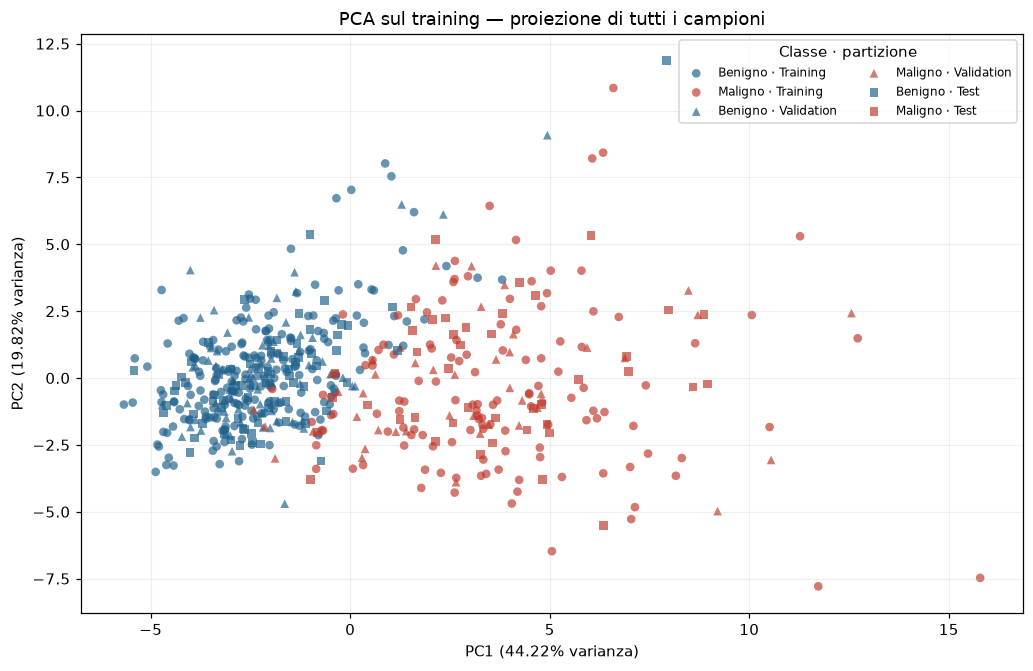

,Componente,Varianza spiegata,Varianza cumulata
0,1,0.4422,0.4422
1,2,0.1982,0.6403
2,3,0.0895,0.7299
3,4,0.0673,0.7971
4,5,0.0541,0.8513
5,6,0.0398,0.8910
6,7,0.0239,0.9149
7,8,0.0172,0.9321
8,9,0.0126,0.9447
9,10,0.0122,0.9569


PC1: 44.22% | PC2: 19.82% | prime due: 64.03%
Componenti necessarie per almeno il 95% della varianza: 10


In [4]:
scaler_pca = StandardScaler().fit(dati_training)
matrice_training_scalata_pca = scaler_pca.transform(dati_training)
matrice_completa_scalata_pca = scaler_pca.transform(matrice_feature)

pca_training = PCA(svd_solver="full").fit(matrice_training_scalata_pca)
proiezione_pca = pca_training.transform(matrice_completa_scalata_pca)

varianza_spiegata = pca_training.explained_variance_ratio_
varianza_cumulata = np.cumsum(varianza_spiegata)
componenti_per_95 = int(np.searchsorted(varianza_cumulata, 0.95) + 1)

partizione = pd.Series("training", index=matrice_feature.index, dtype=object)
partizione.loc[dati_validation.index] = "validation"
partizione.loc[dati_test.index] = "test"

stili_partizione = {
    "training": ("o", "Training"),
    "validation": ("^", "Validation"),
    "test": ("s", "Test"),
}
colori_classe = {0: "#1f618d", 1: "#c0392b"}
nomi_classe = {0: "Benigno", 1: "Maligno"}

figura_pca, asse_pca = plt.subplots(figsize=(9.5, 6.2))
for nome_partizione, (marcatore, etichetta_partizione) in stili_partizione.items():
    for classe in (0, 1):
        maschera = (partizione.to_numpy() == nome_partizione) & (etichette_binarie.to_numpy() == classe)
        asse_pca.scatter(
            proiezione_pca[maschera, 0], proiezione_pca[maschera, 1],
            c=colori_classe[classe], marker=marcatore, s=32, alpha=0.68,
            edgecolors="none",
            label=f"{nomi_classe[classe]} · {etichetta_partizione}",
        )
asse_pca.set_xlabel(f"PC1 ({varianza_spiegata[0]:.2%} varianza)")
asse_pca.set_ylabel(f"PC2 ({varianza_spiegata[1]:.2%} varianza)")
asse_pca.set_title("PCA sul training — proiezione di tutti i campioni")
asse_pca.legend(title="Classe · partizione", fontsize=8, ncol=2, frameon=True)
asse_pca.grid(alpha=0.2)
figura_pca.tight_layout()
plt.show()

riepilogo_pca = pd.DataFrame({
    "Componente": np.arange(1, 11),
    "Varianza spiegata": varianza_spiegata[:10],
    "Varianza cumulata": varianza_cumulata[:10],
})
display(riepilogo_pca.round(4))
print(f"PC1: {varianza_spiegata[0]:.2%} | PC2: {varianza_spiegata[1]:.2%} | "
      f"prime due: {varianza_cumulata[1]:.2%}")
print("Componenti necessarie per almeno il 95% della varianza:", componenti_per_95)


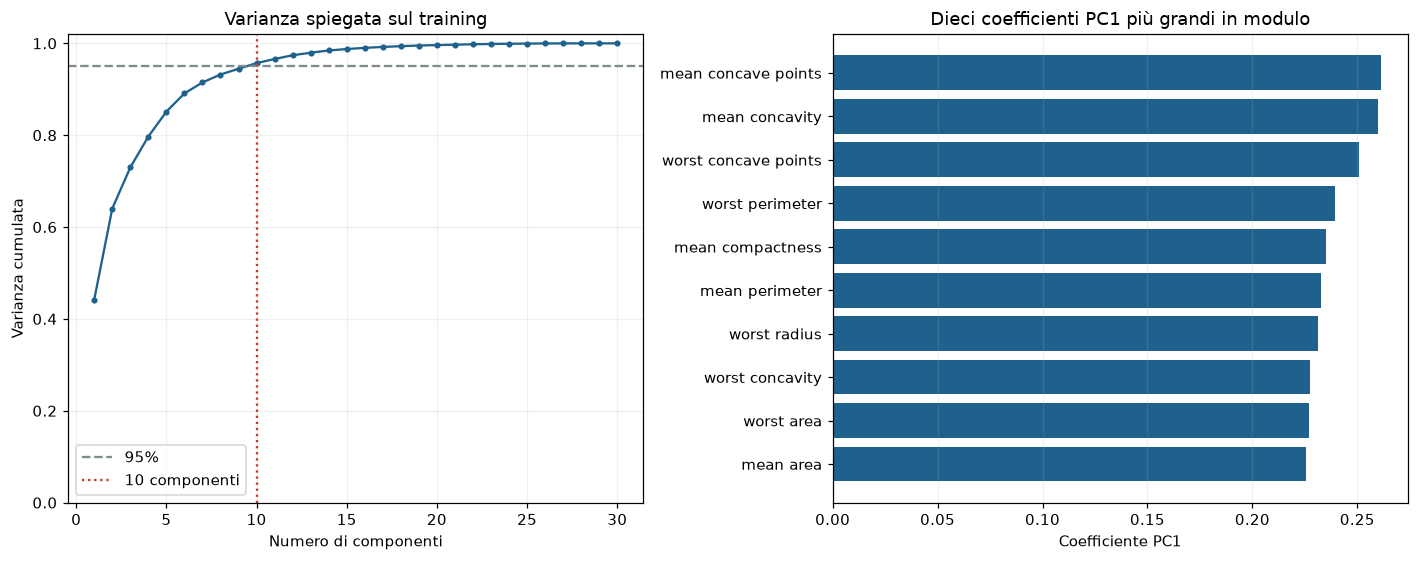

,coefficiente PC1
mean concave points,0.2611
mean concavity,0.2600
worst concave points,0.2508
worst perimeter,0.2395
mean compactness,0.2351
mean perimeter,0.2328
worst radius,0.2312
worst concavity,0.2274
worst area,0.2272
mean area,0.2257


In [5]:
carichi_pc1 = pd.Series(pca_training.components_[0], index=nomi_feature)
feature_pc1_principali = carichi_pc1.abs().sort_values(ascending=False).head(10).index.tolist()

figura_pca_feature, assi_pca = plt.subplots(1, 2, figsize=(13, 5.2))
assi_pca[0].plot(np.arange(1, len(varianza_cumulata) + 1), varianza_cumulata,
                 marker=".", color="#1f618d")
assi_pca[0].axhline(0.95, color="#7f8c8d", linestyle="--", label="95%")
assi_pca[0].axvline(componenti_per_95, color="#c0392b", linestyle=":",
                    label=f"{componenti_per_95} componenti")
assi_pca[0].set(xlabel="Numero di componenti", ylabel="Varianza cumulata",
                title="Varianza spiegata sul training", ylim=(0, 1.02))
assi_pca[0].legend()
assi_pca[0].grid(alpha=0.2)

valori_pc1 = carichi_pc1.loc[feature_pc1_principali[::-1]]
assi_pca[1].barh(feature_pc1_principali[::-1], valori_pc1, color="#1f618d")
assi_pca[1].set(xlabel="Coefficiente PC1",
                title="Dieci coefficienti PC1 più grandi in modulo")
assi_pca[1].grid(axis="x", alpha=0.2)
figura_pca_feature.tight_layout()
plt.show()

display(carichi_pc1.loc[feature_pc1_principali].to_frame("coefficiente PC1").round(4))


## 5. Modelli e scelta sulla validation

Ogni modello riceve gli stessi campioni di training. Regressione logistica, SVM e MLP includono lo StandardScaler nella pipeline, quindi lo scaling viene stimato solo sul training. Random Forest non richiede standardizzazione. La metrica di selezione è la ROC AUC di validation; il test non viene usato in questa fase.


In [6]:
def calcola_metriche(etichette_reali, etichette_predette, punteggi_probabilita):
    matrice = confusion_matrix(etichette_reali, etichette_predette, labels=[0, 1])
    veri_negativi, falsi_positivi, falsi_negativi, veri_positivi = matrice.ravel()
    totale = veri_negativi + falsi_positivi + falsi_negativi + veri_positivi

    accuracy = (veri_positivi + veri_negativi) / totale
    precision = (veri_positivi / (veri_positivi + falsi_positivi)
                 if (veri_positivi + falsi_positivi) else 0.0)
    recall = (veri_positivi / (veri_positivi + falsi_negativi)
              if (veri_positivi + falsi_negativi) else 0.0)
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) else 0.0)

    falsi_positivi_roc, veri_positivi_roc, soglie = roc_curve(
        etichette_reali, punteggi_probabilita
    )
    roc_auc = auc(falsi_positivi_roc, veri_positivi_roc)

    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc),
    }


ARCHITETTURE_MLP = ((64, 32), (256, 128), (512, 256), (1024, 512))
PARAMETRI_COMUNI_MLP = {
    "activation": "relu",
    "solver": "adam",
    "alpha": 1e-4,
    "learning_rate_init": 1e-3,
    "max_iter": 1500,
    "early_stopping": False,
    "n_iter_no_change": 30,
    "random_state": SEME,
}

modelli = {
    "Regressione logistica": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=SEME),
    ),
    "SVM RBF": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", probability=True, random_state=SEME),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=SEME,
        n_jobs=-1,
    ),
}
for architettura in ARCHITETTURE_MLP:
    nome_modello = f"MLP profonda {architettura}"

    modelli[nome_modello] = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=architettura,
            **PARAMETRI_COMUNI_MLP,
        ),
    )

metriche_validation = {}
predizioni_validation = {}
probabilita_validation = {}
curve_roc_validation = {}

for nome_modello, modello in modelli.items():
    modello.fit(dati_training, etichette_training)
    probabilita_validation[nome_modello] = modello.predict_proba(dati_validation)[:, 1]
    predizioni_validation[nome_modello] = modello.predict(dati_validation)
    metriche_validation[nome_modello] = calcola_metriche(
        etichette_validation,
        predizioni_validation[nome_modello],
        probabilita_validation[nome_modello],
    )
    curve_roc_validation[nome_modello] = roc_curve(
        etichette_validation, probabilita_validation[nome_modello]
    )

metriche_validation_dataframe = pd.DataFrame(metriche_validation).T
display(metriche_validation_dataframe.round(4))

modello_selezionato = metriche_validation_dataframe["roc_auc"].idxmax()
print("Modello selezionato tramite ROC AUC di validation:", modello_selezionato)
print("ROC AUC di validation:", f"{metriche_validation_dataframe.loc[modello_selezionato, 'roc_auc']:.6f}")


C:\Users\Leonardo Marafioti\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,accuracy,precision,recall,f1,roc_auc
Regressione logistica,0.9474,0.9744,0.8837,0.9268,0.9820
SVM RBF,0.9386,0.9737,0.8605,0.9136,0.9830
Random Forest,0.9561,0.9750,0.9070,0.9398,0.9844
"MLP profonda (64, 32)",0.9386,0.9500,0.8837,0.9157,0.9797
"MLP profonda (256, 128)",0.9386,0.9500,0.8837,0.9157,0.9817
"MLP profonda (512, 256)",0.9386,0.9500,0.8837,0.9157,0.9807
"MLP profonda (1024, 512)",0.9386,0.9500,0.8837,0.9157,0.9803


Modello selezionato tramite ROC AUC di validation: Random Forest
ROC AUC di validation: 0.984442


## 6. Valutazione finale sul test

Solo dopo aver fissato il modello si calcolano le metriche sul test. La soglia operativa è quella di "predict"; le curve ROC usano le probabilità di "predict_proba". Le metriche di tutti i modelli sono riportate come confronto descrittivo, senza andare però a cambiare retroattivamente la scelta.


In [7]:
metriche_test = {}
predizioni_test = {}
probabilita_test = {}
curve_roc_test = {}
matrici_confusione_test = {}

for nome_modello, modello in modelli.items():
    probabilita_test[nome_modello] = modello.predict_proba(dati_test)[:, 1]
    predizioni_test[nome_modello] = modello.predict(dati_test)
    metriche_test[nome_modello] = calcola_metriche(
        etichette_test,
        predizioni_test[nome_modello],
        probabilita_test[nome_modello],
    )
    curve_roc_test[nome_modello] = roc_curve(
        etichette_test, probabilita_test[nome_modello]
    )
    matrici_confusione_test[nome_modello] = confusion_matrix(
        etichette_test, predizioni_test[nome_modello], labels=[0, 1]
    )

metriche_test_dataframe = pd.DataFrame(metriche_test).T
matrice_confusione_selezionata = matrici_confusione_test[modello_selezionato]

predizioni_test_dataframe = pd.DataFrame({
    "indice": dati_test.index,
    "classe_reale_maligno": etichette_test.to_numpy(),
})
for nome_modello in modelli:
    predizioni_test_dataframe[f"{nome_modello} predizione"] = predizioni_test[nome_modello]
    predizioni_test_dataframe[f"{nome_modello} probabilita"] = probabilita_test[nome_modello]

display(metriche_test_dataframe.round(4))

etichette_classi = ["Benigno (0)", "Maligno (1)"]
matrice_confusione_selezionata_dataframe = pd.DataFrame(
    matrice_confusione_selezionata,
    index=[f"Reale {etichetta}" for etichetta in etichette_classi],
    columns=[f"Predetto {etichetta}" for etichetta in etichette_classi],
)
display(matrice_confusione_selezionata_dataframe)

errori_modello_selezionato = predizioni_test_dataframe.loc[
    predizioni_test_dataframe["classe_reale_maligno"] !=
    predizioni_test_dataframe[f"{modello_selezionato} predizione"]
]
print("Errori del modello selezionato:", len(errori_modello_selezionato))
colonne_errori_selezionate = [
    "indice",
    "classe_reale_maligno",
    f"{modello_selezionato} predizione",
    f"{modello_selezionato} probabilita",
]
display(errori_modello_selezionato[colonne_errori_selezionate].round(4))


,accuracy,precision,recall,f1,roc_auc
Regressione logistica,0.9737,0.9756,0.9524,0.9639,0.9970
SVM RBF,0.9737,0.9535,0.9762,0.9647,0.9983
Random Forest,0.9649,0.9318,0.9762,0.9535,0.9950
"MLP profonda (64, 32)",0.9474,0.9286,0.9286,0.9286,0.9934
"MLP profonda (256, 128)",0.9649,0.9524,0.9524,0.9524,0.9954
"MLP profonda (512, 256)",0.9474,0.9500,0.9048,0.9268,0.9927
"MLP profonda (1024, 512)",0.9561,0.9512,0.9286,0.9398,0.9931


,Predetto Benigno (0),Predetto Maligno (1)
Reale Benigno (0),69,3
Reale Maligno (1),1,41


Errori del modello selezionato: 4


,indice,classe_reale_maligno,Random Forest predizione,Random Forest probabilita
46,157,0,1,0.7700
72,484,0,1,0.5925
77,81,0,1,0.6425
89,38,1,0,0.1575


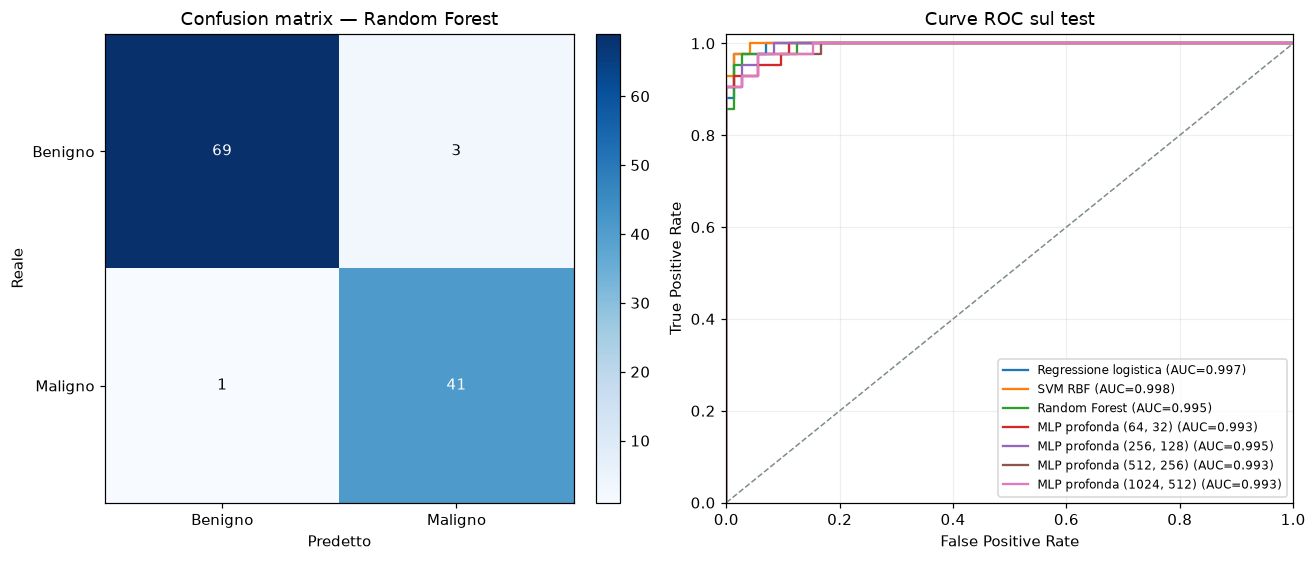

In [8]:
figura_valutazione, assi_valutazione = plt.subplots(1, 2, figsize=(12.5, 5.2))

immagine = assi_valutazione[0].imshow(matrice_confusione_selezionata, cmap="Blues")
assi_valutazione[0].set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"],
    xlabel="Predetto", ylabel="Reale",
    title=f"Confusion matrix — {modello_selezionato}",
)
limite_colore = matrice_confusione_selezionata.max()
for riga in range(2):
    for colonna in range(2):
        valore = matrice_confusione_selezionata[riga, colonna]
        assi_valutazione[0].text(
            colonna, riga, str(valore), ha="center", va="center",
            color="white" if valore > limite_colore / 2 else "black",
        )
figura_valutazione.colorbar(immagine, ax=assi_valutazione[0], fraction=0.046, pad=0.04)

for nome_modello in modelli:
    falsi_positivi, veri_positivi, _ = curve_roc_test[nome_modello]
    assi_valutazione[1].plot(
        falsi_positivi, veri_positivi,
        label=f"{nome_modello} (AUC={metriche_test_dataframe.loc[nome_modello, 'roc_auc']:.3f})",
    )
assi_valutazione[1].plot([0, 1], [0, 1], "--", color="#7f8c8d", linewidth=1)
assi_valutazione[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate",
                        title="Curve ROC sul test", xlim=(0, 1), ylim=(0, 1.02))
assi_valutazione[1].legend(fontsize=8, loc="lower right")
assi_valutazione[1].grid(alpha=0.2)
figura_valutazione.tight_layout()
plt.show()


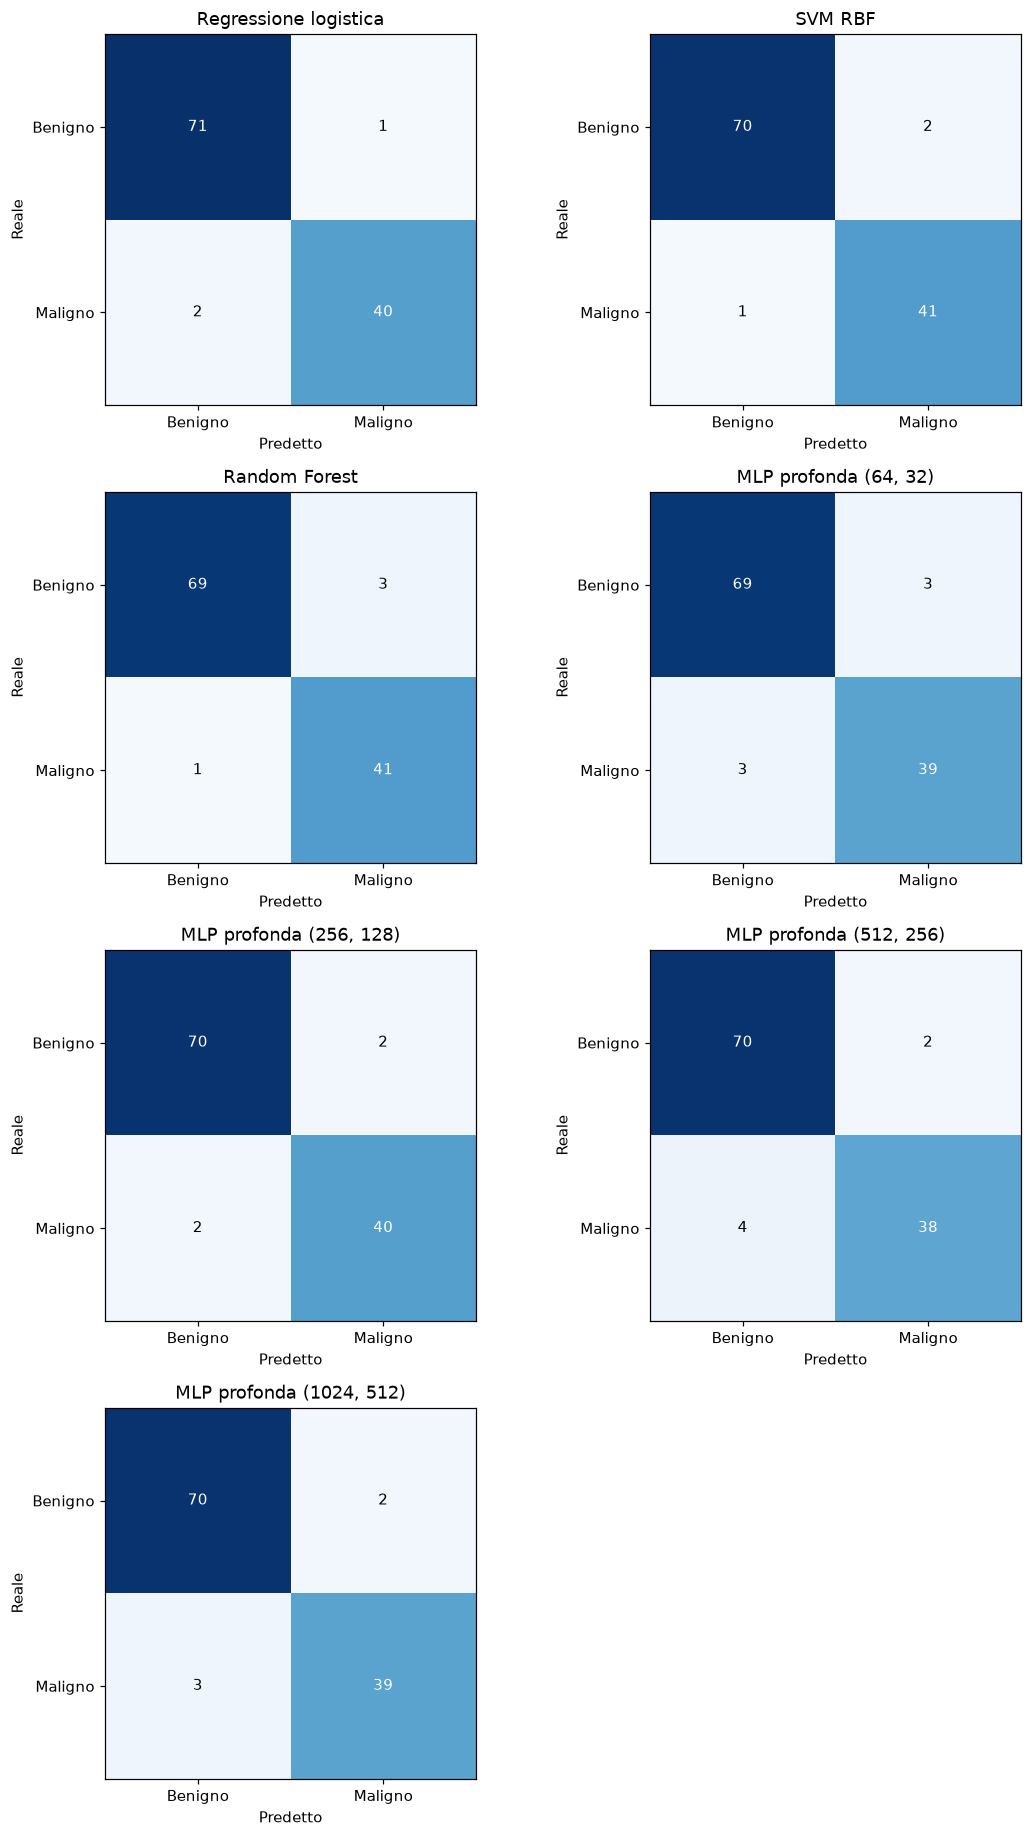

In [9]:
numero_righe = int(np.ceil(len(modelli) / 2))
figura_matrice_confusione, assi_confusione = plt.subplots(
    numero_righe, 2, figsize=(10.5, 4.2 * numero_righe), squeeze=False
)
limite_comune = max(matrice.max() for matrice in matrici_confusione_test.values())

for asse_confusione, (nome_modello, matrice) in zip(
    assi_confusione.flat, matrici_confusione_test.items()
):
    asse_confusione.imshow(matrice, cmap="Blues", vmin=0, vmax=limite_comune)
    asse_confusione.set(
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"],
        xlabel="Predetto", ylabel="Reale", title=nome_modello,
    )
    for riga in range(2):
        for colonna in range(2):
            valore = matrice[riga, colonna]
            asse_confusione.text(
                colonna, riga, str(valore), ha="center", va="center",
                color="white" if valore > limite_comune / 2 else "black",
            )
for asse_inutilizzato in assi_confusione.flat[len(matrici_confusione_test):]:
    asse_inutilizzato.remove()
figura_matrice_confusione.tight_layout()
plt.show()


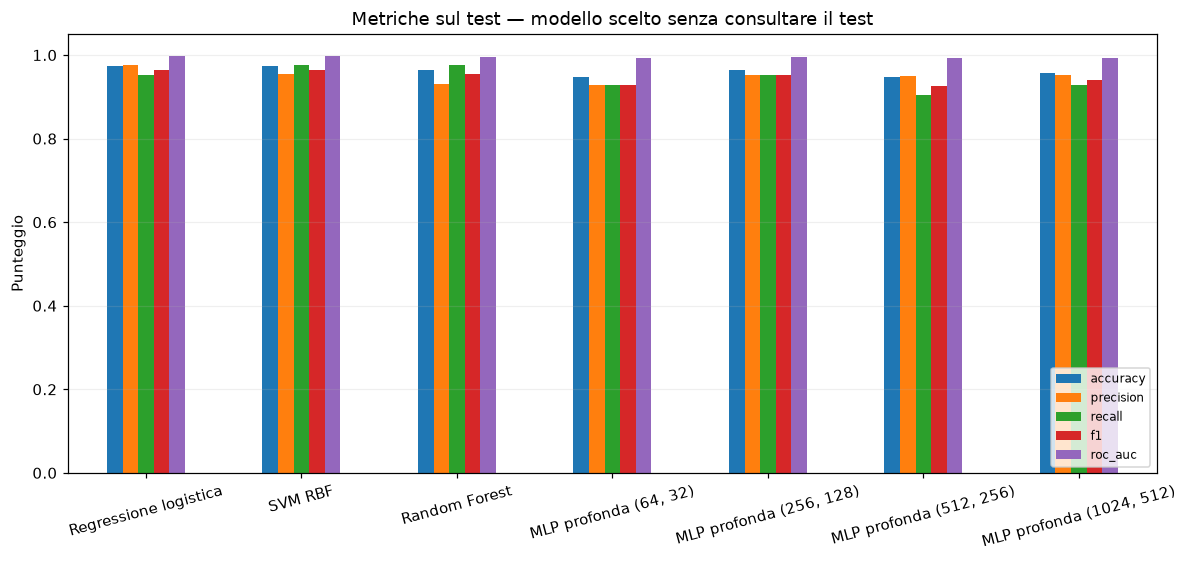

In [10]:
figura_metriche, asse_metriche = plt.subplots(figsize=(11, 5.2))
metriche_test_dataframe[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", ax=asse_metriche, ylim=(0, 1.05), rot=15
)
asse_metriche.set_ylabel("Punteggio")
asse_metriche.set_title("Metriche sul test — modello scelto senza consultare il test")
asse_metriche.grid(axis="y", alpha=0.2)
asse_metriche.legend(loc="lower right", fontsize=8)
figura_metriche.tight_layout()
plt.show()


## 7. Dettagli della rete neurale

La MLP è l'approfondimento di deep learning. ARCHITETTURE_MLP in cella 5 contiene quattro esempi  di due strati nascosti indicati come (primo livello, secondo livello): (64, 32), (256, 128), (512, 256) e (1024, 512). Da quel solo elenco derivano i modelli, i nomi nelle tabelle e i titoli dei grafici; cambia i nodi modificando la tupla, non il testo. Per isolare l'effetto della capacità, tutte le architetture condividono PARAMETRI_COMUNI_MLP, stessi split e preprocessing.

Le taglie crescenti confrontano una rete compatta con reti più capienti: più unità aumentano i parametri e la capacità di rappresentare interazioni non lineari, ma anche costo, rischio di overfitting e sensibilità su un dataset piccolo (341 esempi di training). Il confronto è a scopo didattico (curiosità personale), non una ricerca esaustiva né una prova che la rete più grande sia migliore. alpha pari a 1e-4 applica una penalità L2 moderata; Adam con learning rate 1e-3 è una scelta standard stabile secondo letteratura (e corso); limite 1500 iterazioni e pazienza 30 consentono convergenza senza imporre un numero fisso di epoche. L'early stopping è disabilitato per usare tutto il training e mantenere la validation esterna comune. Le architetture sono selezionate solo tramite ROC AUC validation, mai test.

### 7.1 Spiegabilità locale con LIME

LIME approssima localmente il classificatore selezionato con un modello interpretabile: perturba le feature intorno a un singolo campione e stima quali variabili spostano la probabilità verso la classe maligna o benigna. Le feature continue restano non discretizzate, così i contributi sono riferiti alle variabili originali senza intervalli arrotondati poco leggibili. I dati di training sono usati come distribuzione di riferimento; il caso spiegato è il campione di validation con probabilità maligna più vicina a 0,5, quindi un caso borderline scelto senza consultare il test. Il punteggio di fedeltà misura l'aderenza del surrogate nel vicinato generato, non la qualità globale del classificatore. Le attribuzioni sono locali, non causali, e possono risentire della correlazione tra feature.


,valore
Architettura,30 input → 64 ReLU → 32 ReLU → 1 output
Ottimizzatore,adam
Regolarizzazione L2 (alpha),0.0001
Learning rate iniziale,0.001
Iterazioni eseguite,201
Loss finale sul training,0.00392
Parametri addestrabili,4097
Early stopping,False
Pazienza,30


,valore
Modello spiegato,Random Forest
Indice del campione validation,406
Classe reale,0
Probabilità prevista di maligno,0.48
Fedeltà locale LIME,0.451058


,Feature e intervallo,Contributo locale alla classe maligna
9,texture error,0.010180
8,mean concavity,0.013700
7,mean perimeter,0.016971
6,mean radius,0.018386
5,worst texture,0.018437
4,area error,0.018515
3,mean area,0.019112
2,mean texture,0.024867
1,worst perimeter,0.056932
0,worst radius,0.057015


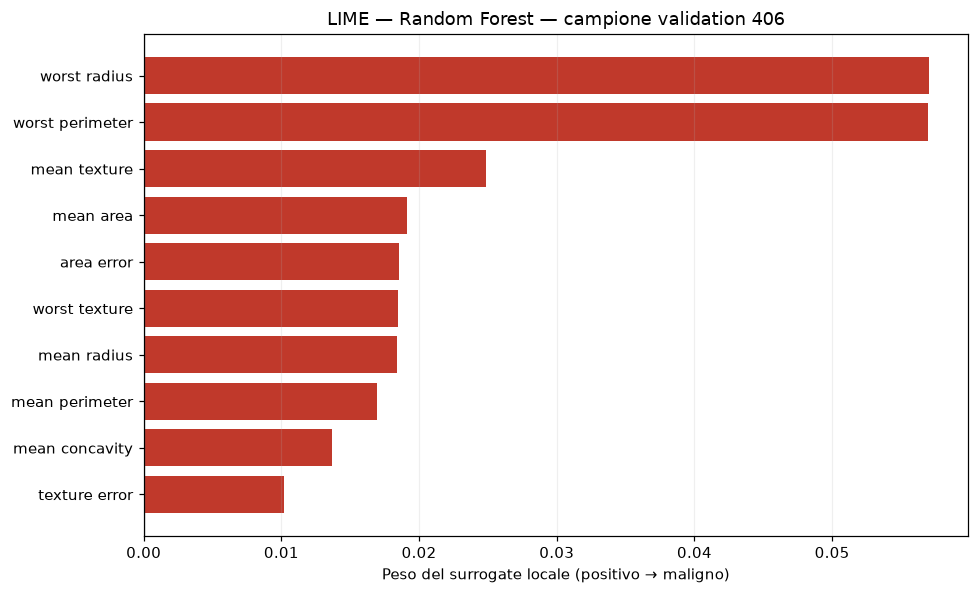

In [11]:
nome_mlp_dettaglio = f"MLP profonda {ARCHITETTURE_MLP[0]}"
mlp_addestrata = modelli[nome_mlp_dettaglio].named_steps["mlpclassifier"]
iterazioni_mlp = int(mlp_addestrata.n_iter_)
numero_parametri_mlp = int(
    sum(peso.size for peso in mlp_addestrata.coefs_) +
    sum(bias.size for bias in mlp_addestrata.intercepts_)
)

riepilogo_mlp = pd.Series({
    "Architettura": (
        f"{matrice_feature.shape[1]} input → "
        + " → ".join(f"{n} ReLU" for n in mlp_addestrata.hidden_layer_sizes)
        + " → 1 output"
    ),
    "Ottimizzatore": mlp_addestrata.solver,
    "Regolarizzazione L2 (alpha)": mlp_addestrata.alpha,
    "Learning rate iniziale": mlp_addestrata.learning_rate_init,
    "Iterazioni eseguite": iterazioni_mlp,
    "Loss finale sul training": float(mlp_addestrata.loss_),
    "Parametri addestrabili": numero_parametri_mlp,
    "Early stopping": mlp_addestrata.early_stopping,
    "Pazienza": mlp_addestrata.n_iter_no_change,
}, name="valore")
display(riepilogo_mlp.to_frame())

NUMERO_CAMPIONI_LIME = 3000
NUMERO_FEATURE_LIME = 10
indice_posizione_lime = int(np.argmin(
    np.abs(probabilita_validation[modello_selezionato] - 0.5)
))
indice_campione_lime = dati_validation.index[indice_posizione_lime]
campione_lime = dati_validation.iloc[indice_posizione_lime]

def predici_probabilita_lime(matrice_perturbata):
    dati_perturbati = pd.DataFrame(matrice_perturbata, columns=nomi_feature)
    return modelli[modello_selezionato].predict_proba(dati_perturbati)

spiegatore_lime = LimeTabularExplainer(
    training_data=dati_training.to_numpy(),
    feature_names=nomi_feature,
    class_names=["Benigno (0)", "Maligno (1)"],
    mode="classification",
    discretize_continuous=False,
    sample_around_instance=True,
)
spiegazione_lime = spiegatore_lime.explain_instance(
    campione_lime.to_numpy(),
    predici_probabilita_lime,
    labels=(1,),
    num_features=min(NUMERO_FEATURE_LIME, len(nomi_feature)),
    num_samples=NUMERO_CAMPIONI_LIME,
)

display(pd.Series({
    "Modello spiegato": modello_selezionato,
    "Indice del campione validation": int(indice_campione_lime),
    "Classe reale": int(etichette_validation.iloc[indice_posizione_lime]),
    "Probabilità prevista di maligno": float(
        probabilita_validation[modello_selezionato][indice_posizione_lime]
    ),
    "Fedeltà locale LIME": float(spiegazione_lime.score),
}, name="valore").to_frame())

contributi_lime = pd.DataFrame(
    spiegazione_lime.as_list(label=1),
    columns=["Feature e intervallo", "Contributo locale alla classe maligna"],
).sort_values("Contributo locale alla classe maligna")
display(contributi_lime)

figura_lime, asse_lime = plt.subplots(figsize=(9, 5.5))
colori_lime = [
    "#c0392b" if contributo > 0 else "#1f618d"
    for contributo in contributi_lime["Contributo locale alla classe maligna"]
]
asse_lime.barh(
    contributi_lime["Feature e intervallo"],
    contributi_lime["Contributo locale alla classe maligna"],
    color=colori_lime,
)
asse_lime.axvline(0, color="#566573", linewidth=0.8)
asse_lime.set(
    xlabel="Peso del surrogate locale (positivo → maligno)",
    title=f"LIME — {modello_selezionato} — campione validation {indice_campione_lime}",
)
asse_lime.grid(axis="x", alpha=0.2)
figura_lime.tight_layout()
plt.show()


## 8. Limiti e conclusioni

Il dataset è piccolo, storico e non rappresenta necessariamente popolazioni, ospedali o strumenti diversi.

La PCA mostra una struttura correlata e una separazione parziale tra le classi, ma i classificatori usano tutte le 30 feature originali. Il contributo dell'esperimento è il confronto riproducibile, con trasformazioni stimate solo sul training e selezione distinta dalla valutazione finale.

